# Prescriptive Analytics Project - Winter Term 2024/25 - Murat Tutar

___
#### **Question 1**
___

In [1]:
# import packages here:
#import graphviz
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats
import sys
from gurobipy import Model, GRB

a) Analyse the data given and provide clusters: Are there differences/ similarities between some days of the week? Evaluate which days could be weekdays and which days could be weekend days. At which times of the days does the data look similarly distributed? At which times does it differ? We do not expect you to fit distributions but recommend to analyse the data using visualisations.

In [2]:
# Load data and create a dataframe 'data_df'
data_df = pd.read_csv("Project_Data.csv", sep=';', index_col='index')

print(data_df)

       Week 1  Week 2  Week 3  Week 4  Week 5  Week 6  Week 7  Week 8  Week 9  \
index                                                                           
1           1       2       0       1       0       0       2       1       1   
2           1       1       0       1       0       0       2       1       2   
3           1       1       0       1       0       0       2       1       2   
4           1       1       0       1       0       0       2       1       0   
5           1       2       0       1       0       0       2       1       1   
...       ...     ...     ...     ...     ...     ...     ...     ...     ...   
164         2       2       0       1       4       2       2       2       2   
165         1       2       0       2       3       2       2       1       3   
166         1       1       0       2       0       0       2       1       0   
167         1       1       0       1       0       0       2       1       0   
168         1       1       

In [3]:
# Reset the index to ensure it starts from 0
data_df.reset_index(drop=True, inplace=True)

# Create a column for hours, ensuring the first row corresponds to hour 0
data_df['hour'] = data_df.index % 24  # Cycle hours from 0 to 23

# Create a column for days, grouping each 24-hour period as one day
data_df['day'] = data_df.index // 24 + 1  # Day 1 corresponds to hours 0–23, Day 2 to 24–47, etc.

# Function to assign shifts based on the hour
def assign_shift(hour):
    if 8 <= hour < 16:
        return "early"  # Early shift: 8 AM to 4 PM
    elif 16 <= hour < 24:
        return "late"  # Late shift: 4 PM to 12 AM
    else:
        return "night"  # Night shift: 12 AM to 8 AM

# Apply the shift assignment to the DataFrame
data_df['shift'] = data_df['hour'].apply(assign_shift)

# Display the updated DataFrame
print(data_df.head(20))  # Show the first 20 rows to confirm the added columns

    Week 1  Week 2  Week 3  Week 4  Week 5  Week 6  Week 7  Week 8  Week 9  \
0        1       2       0       1       0       0       2       1       1   
1        1       1       0       1       0       0       2       1       2   
2        1       1       0       1       0       0       2       1       2   
3        1       1       0       1       0       0       2       1       0   
4        1       2       0       1       0       0       2       1       1   
5        1       1       0       1       0       0       2       1       0   
6        1       2       0       1       0       0       2       1       1   
7        1       7       8       9       6       7       9       7      10   
8        9       9       8      10       8       7       9       9       9   
9       10       8      11      10       9       9      12       9      12   
10      11      11       9      10      12      11       9      11      10   
11      10      11      10      11      11      11       9      

In [4]:
# Filter the data to only include days 1 to 7
filtered_data = data_df[data_df['day'].isin(range(1, 8))]

# Define the weekly columns
weekly_columns = [col for col in data_df.columns if 'Week' in col]

# Group the data by day and sum the weekly columns
day_summary = filtered_data.groupby('day')[weekly_columns].sum()

# Rename the index for clarity
day_summary.index.name = 'Day'

# Display the summarized data
print(day_summary)

     Week 1  Week 2  Week 3  Week 4  Week 5  Week 6  Week 7  Week 8  Week 9  \
Day                                                                           
1       118     103      91      91      97      95      83     133     101   
2       136     109      94      56     113      96     101     155     102   
3       117      99      96      80     101      84      89     121      98   
4       112     123      97      69     120      96     100     114     107   
5         7      24       0       4      11      15       4      15      16   
6         6       3       3       0       4       8       0       0       1   
7       111     102      71     117     113     109      99      90     104   

     Week 10  Week 11  Week 12  Week 13  Week 14  
Day                                               
1        102      102      104       78       97  
2         92      113      113       53      110  
3         98       77      114       53      101  
4        121      149       75   

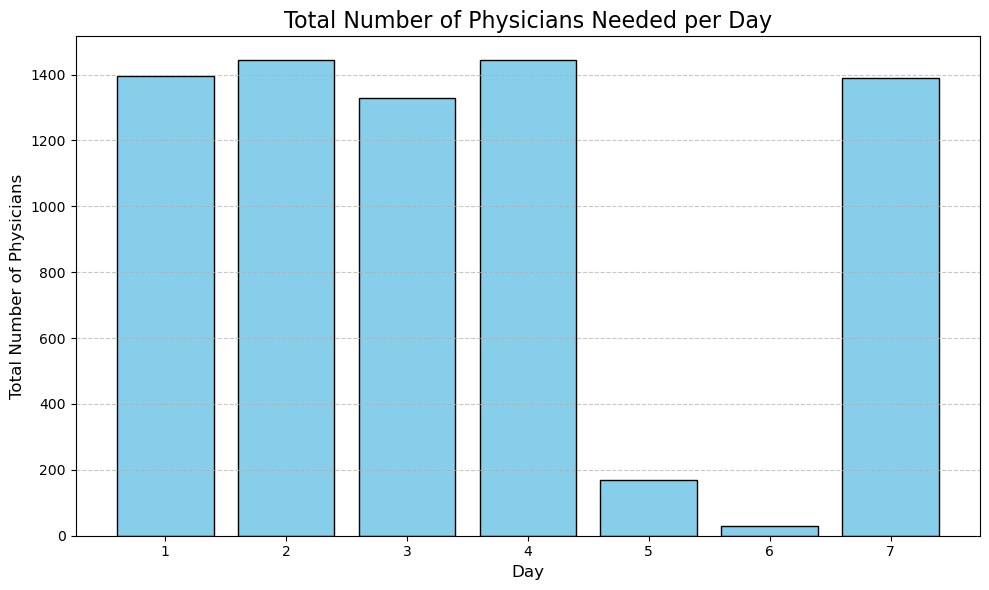

In [5]:
# Calculate the total number of Physicians needed per day (sum across weeks)
total_per_day = day_summary.sum(axis=1)

# Plot the total number of Physicians needed per day as a bar chart
plt.figure(figsize=(10, 6))
plt.bar(total_per_day.index, total_per_day, color='skyblue', edgecolor='black')

# Add labels and title
plt.title("Total Number of Physicians Needed per Day", fontsize=16)
plt.xlabel("Day", fontsize=12)
plt.ylabel("Total Number of Physicians", fontsize=12)

# Customize x-ticks
plt.xticks(total_per_day.index)

# Add grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()


1. Are there differences/similarities between some days of the week?

- Similarities: Days 1, 2, 4, and 7 have a very high and almost similar total number of physicians needed, indicating they follow a similar trend in workload.
- Differences: Days 5 and 6 have significantly lower numbers compared to the other days, with Day 6 showing the least requirement overall. This strong contrast suggests differences in workload distribution across the week.

2. Evaluate which days could be weekdays and which days could be weekend days.

- Potential weekdays: Days 1, 2, 4, and 7. The high number of physicians needed on these days suggests they could correspond to typical weekdays with regular work schedules.
- Potential weekend days: Days 5 and 6. The noticeably lower requirements for these days might indicate they are part of the weekend, where demand for physicians typically decreases.

Total Physicians Needed for Each Shift Across All Days:
shift
early    5132
late     1211
night     857
dtype: int64


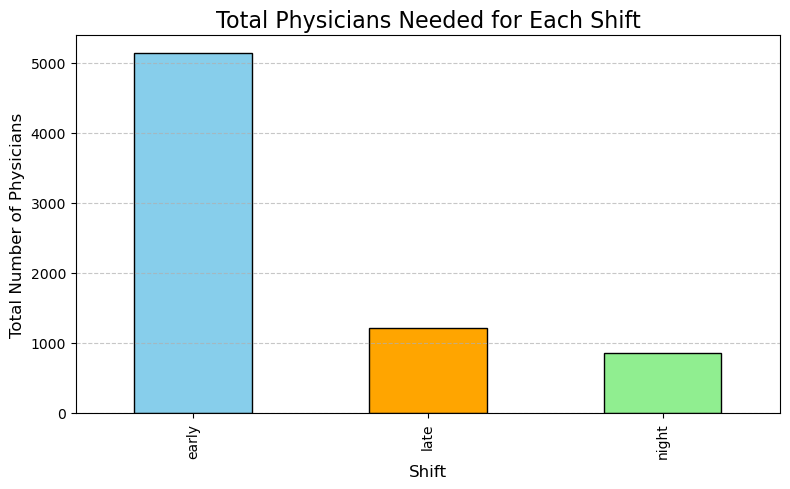

In [6]:
# Define weekly columns
weekly_columns = [col for col in data_df.columns if 'Week' in col]

# Group by shift and sum the weekly columns
shift_summary = data_df.groupby('shift')[weekly_columns].sum()

# Calculate the total physicians needed for each shift
total_per_shift = shift_summary.sum(axis=1)

# Display the totals as text output
print("Total Physicians Needed for Each Shift Across All Days:")
print(total_per_shift)

# Plot the total physicians needed for each shift as a bar chart
plt.figure(figsize=(8, 5))
total_per_shift.plot(kind='bar', color=['skyblue', 'orange', 'lightgreen'], edgecolor='black')

# Add labels and title
plt.title("Total Physicians Needed for Each Shift", fontsize=16)
plt.xlabel("Shift", fontsize=12)
plt.ylabel("Total Number of Physicians", fontsize=12)

# Add grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()

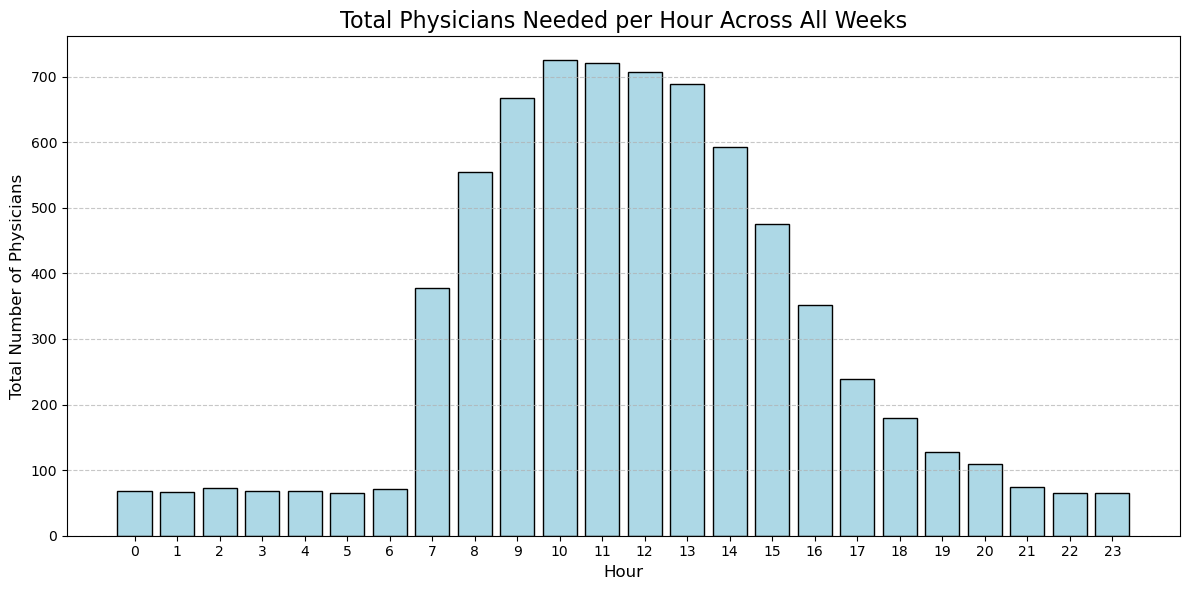

In [7]:
# Define weekly columns
weekly_columns = [col for col in data_df.columns if 'Week' in col]

# Group by hour and sum the weekly columns
hourly_summary = data_df.groupby('hour')[weekly_columns].sum()

# Calculate the total physicians needed for each hour across all weeks
total_per_hour = hourly_summary.sum(axis=1)

# Plot the total physicians needed per hour as a bar chart
plt.figure(figsize=(12, 6))
plt.bar(total_per_hour.index, total_per_hour, color='lightblue', edgecolor='black')

# Add labels and title
plt.title("Total Physicians Needed per Hour Across All Weeks", fontsize=16)
plt.xlabel("Hour", fontsize=12)
plt.ylabel("Total Number of Physicians", fontsize=12)

# Customize x-ticks
plt.xticks(range(0, 24))

# Add grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()

3. At which times of the day does the data look similarly distributed?

- Midnight to early morning (0:00 - 6:00): The number of physicians needed is consistently low and relatively stable during these hours, suggesting a minimal workload during late-night and early-morning shifts.
- Morning to early afternoon (8:00 - 14:00): The data shows a high and stable number of physicians needed, peaking during these hours. This indicates these are the busiest times of the day with similar distribution across this period.

4. At which times does it differ?
- Transition periods (7:00 and 15:00):
At 7:00, there is a sharp increase in demand, marking the start of the busy period.
At 15:00, there is a steep drop in demand, signaling the end of the busiest period of the day.
- Evening to night (16:00 - 23:00): The demand gradually decreases, showing more variation compared to the steady high demand during peak hours (8:00 - 14:00). The distribution during these hours reflects the winding down of activities.

b) Give the mean, median, standard deviation, maximum and minimum for each shift type in your cluster.

In [8]:
# Define weekly columns
weekly_columns = [col for col in data_df.columns if 'Week' in col]

# Group by shift and calculate statistics per week
weekly_stats = data_df.groupby('shift')[weekly_columns].aggregate(['mean', 'median', 'std', 'max', 'min'])

# Display the results
print("Statistics for Each Shift Type per Week:")
print(weekly_stats)


Statistics for Each Shift Type per Week:
         Week 1                             Week 2                           \
           mean median       std max min      mean median       std max min   
shift                                                                         
early  7.142857    9.0  4.852098  15   0  6.767857    8.0  4.496427  14   0   
late   2.160714    1.0  2.069491   9   0  1.785714    1.0  1.932632   8   0   
night  1.535714    1.0  1.705225   6   0  1.500000    1.0  1.963300   9   0   

       ...   Week 13                            Week 14                       \
       ...      mean median       std max min      mean median       std max   
shift  ...                                                                     
early  ...  5.517857    6.5  4.164748  12   0  6.446429    8.0  4.331364  12   
late   ...  0.500000    0.0  1.206045   6   0  2.125000    1.5  2.304640   8   
night  ...  0.000000    0.0  0.000000   0   0  0.535714    0.0  0.686607   2   

   

In [9]:
# Define weekly columns
weekly_columns = [col for col in data_df.columns if 'Week' in col]

# Group by shift and flatten the weekly data to calculate statistics over all values
shift_values = data_df.groupby('shift')[weekly_columns].apply(lambda x: x.values.flatten())

# Calculate statistics for each shift type
shift_stats = shift_values.apply(lambda x: pd.Series({
    'mean': x.mean(),
    'median': np.median(x),
    'std': x.std(),
    'max': x.max(),
    'min': x.min()
}))

# Display the results
print("Statistics for Each Shift Type:")
print(shift_stats)


Statistics for Each Shift Type:
           mean  median       std   max  min
shift                                       
early  6.545918     8.0  4.431213  15.0  0.0
late   1.544643     1.0  1.868932   9.0  0.0
night  1.093112     0.0  1.904011  11.0  0.0


___
#### **Question 2**
___

The physicians work in three 8 – hour shifts per day with the first shift starting at 8.00 am and
finishing at 4.00 pm (“early shift”), the second going from 4.00 pm until 12.00 pm (“late shift”)
and the last going from 0.00 am to 8.00 am of the following day (“night shift”). Note that between
shifts they have to take at least 10 hours off. In total, they are allowed to work 40 hours a week
and should have two consecutive days off. Physicians can only work two kind of shifts per
week, that is, either they work early and late shifts, or they work late and night shifts, or they
work night and early shifts. Moreover, they are not allowed to work more than three consecutive
night shifts.

As physicians are expensive employees you do not want to have slack physicians and
minimise the total number of anaesthesiologists you require. However, you always want
enough physicians to be present to cover the demand that you derived from previous data at
each hour and there always has to be one physician on duty in case of emergencies.

Formulate the minimisation problem explaining each constraint and the objective. Solve the
problem and present your schedule for one week, where we assume that the plan is cyclic, i.e.
it ends on Sunday and starts again on Monday. Thus, working the late shift on Sunday and
then working the early shift on Monday morning again is not possible for one physician.

In [10]:
# Calculate the average demand for the seven days of the week and the three different shifts. Based on these averages over the 14 weeks,
# we plan our shift schedule, assuming that the demand in the planned week will be similar to these averages.
# Additionally, further clarification is needed regarding the chosen approach (e.g., maximum values or cost-risk tradeoff),
# as well as a detailed explanation of the underlying assumptions.

# Initialize a list to store results
results_list = []

# Loop through each day (1 to 7) and each shift type (early, night, late)
for day in range(1, 8):  # Loop through days 1 to 7
    for shift in ['early', 'night', 'late']:  # Loop through shift types
        # Filter the DataFrame for the specific day and shift
        filtered_data = data_df[(data_df['day'] == day) & (data_df['shift'] == shift)]
        
        # Sum the values for each week (columns with 'Week' in the name)
        weekly_totals = filtered_data[weekly_columns].sum()
        
        # Calculate the average over the 14 weeks
        average_shifts_day = weekly_totals.mean()
        
        # Calculate the average per hour by dividing by 8 hours (for a shift)
        average_shifts_per_hour = average_shifts_day / 8
        
        # Round the result to the nearest whole number
        average_shifts_per_hour_rounded = round(average_shifts_per_hour)
        
        # Append the result to the list
        results_list.append({'Day': day, 'Shift': shift, 'Average Shifts per Hour': average_shifts_per_hour_rounded})

# Create a DataFrame from the results list
results_df = pd.DataFrame(results_list)

# Pivot the DataFrame to have days as rows and shift types as columns
pivoted_results = results_df.pivot(index='Day', columns='Shift', values='Average Shifts per Hour')

# Display the results
print(pivoted_results)

Shift  early  late  night
Day                      
1          9     2      2
2          9     2      2
3          8     2      1
4          9     2      2
5          0     0      1
6          0     0      0
7          9     2      1


In [11]:
# Create an overview table of the Gurobi solutions, demonstrating that the demand (calculated as the averages from the DataFrame)
# is fulfilled within the Gurobi analysis.

results = """
Physician 0 works early shift on Day 1
Physician 0 works early shift on Day 4
Physician 0 works early shift on Day 7
Physician 1 works early shift on Day 1
Physician 1 works early shift on Day 7
Physician 1 works night shift on Day 3
Physician 2 works early shift on Day 4
Physician 2 works late shift on Day 6
Physician 2 works night shift on Day 2
Physician 3 works early shift on Day 1
Physician 3 works early shift on Day 7
Physician 3 works late shift on Day 3
Physician 4 works early shift on Day 2
Physician 4 works early shift on Day 7
Physician 4 works late shift on Day 4
Physician 5 works early shift on Day 4
Physician 5 works night shift on Day 2
Physician 6 works early shift on Day 4
Physician 6 works early shift on Day 7
Physician 6 works late shift on Day 2
Physician 7 works early shift on Day 2
Physician 7 works early shift on Day 4
Physician 8 works early shift on Day 2
Physician 8 works night shift on Day 7
Physician 9 works early shift on Day 1
Physician 9 works early shift on Day 3
Physician 9 works early shift on Day 5
Physician 10 works early shift on Day 3
Physician 10 works early shift on Day 7
Physician 10 works late shift on Day 1
Physician 11 works early shift on Day 3
Physician 11 works late shift on Day 1
Physician 12 works early shift on Day 1
Physician 12 works early shift on Day 3
Physician 12 works night shift on Day 6
Physician 13 works early shift on Day 2
Physician 13 works early shift on Day 7
Physician 13 works night shift on Day 4
Physician 14 works early shift on Day 2
Physician 14 works night shift on Day 5
Physician 15 works early shift on Day 3
Physician 15 works early shift on Day 7
Physician 15 works late shift on Day 5
Physician 15 works night shift on Day 1
Physician 16 works early shift on Day 2
Physician 16 works early shift on Day 4
Physician 17 works early shift on Day 3
Physician 17 works late shift on Day 7
Physician 17 works night shift on Day 1
Physician 18 works early shift on Day 1
Physician 18 works early shift on Day 3
Physician 19 works early shift on Day 1
Physician 19 works early shift on Day 6
Physician 19 works late shift on Day 3
Physician 20 works early shift on Day 2
Physician 20 works early shift on Day 4
Physician 21 works early shift on Day 2
Physician 21 works early shift on Day 7
Physician 21 works night shift on Day 4
Physician 22 works late shift on Day 2
Physician 22 works late shift on Day 4
Physician 23 works early shift on Day 2
Physician 23 works early shift on Day 4
Physician 23 works late shift on Day 7
Physician 24 works early shift on Day 1
Physician 24 works early shift on Day 3
Physician 25 works early shift on Day 1
Physician 25 works early shift on Day 4
"""

# Split the results into lines
lines = results.strip().split("\n")
from collections import Counter

# Data structure for counting shifts
shift_counts = Counter()

# Extract and count data
for line in lines:
    parts = line.split()
    if len(parts) >= 6:
        shift = parts[3]  # Extract the shift type
        # Combine "Day" with the number
        if parts[-2] == "Day":
            day = f"{parts[-2]} {parts[-1]}"  # Create "Day X" format
        else:
            day = parts[-1]  # Fallback, though this shouldn't happen
       
        shift_counts[(shift, day)] += 1
for line in lines:
    parts = line.split()
    if len(parts) >= 6:
        shift = parts[3]  # Extract the shift type ("early", "late", "night")
        day = parts[-1]   # Extract the day ("Day X")
        shift_counts[(shift, day)] += 1

# Initialize all days and shifts
days = [f"Day {i}" for i in range(1, 8)]
shifts = ["early", "night", "late"]

# Create a table to store results
data = {day: {shift: 0 for shift in shifts} for day in days}

# Populate the table with counts
for (shift, day), count in shift_counts.items():
    if day in days:
        data[day][shift] = count

# Create a DataFrame from the data
df = pd.DataFrame(data).T  # Transpose so days are rows
df = df[shifts]  # Ensure the correct column order

# Display the table
print(df)

# Optional: Save the table as an Excel or CSV file
df.to_excel("shift_summary.xlsx", index_label="Day")
df.to_csv("shift_summary.csv", index_label="Day")

       early  night  late
Day 1      9      2     2
Day 2      9      2     2
Day 3      8      1     2
Day 4      9      2     2
Day 5      1      1     1
Day 6      1      1     1
Day 7      9      1     2


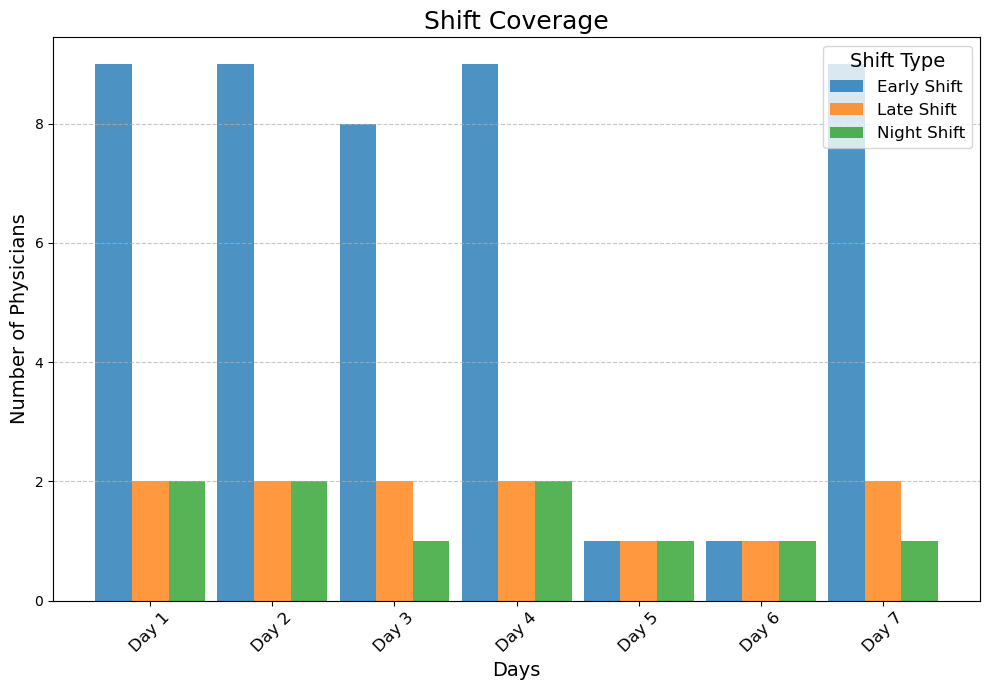

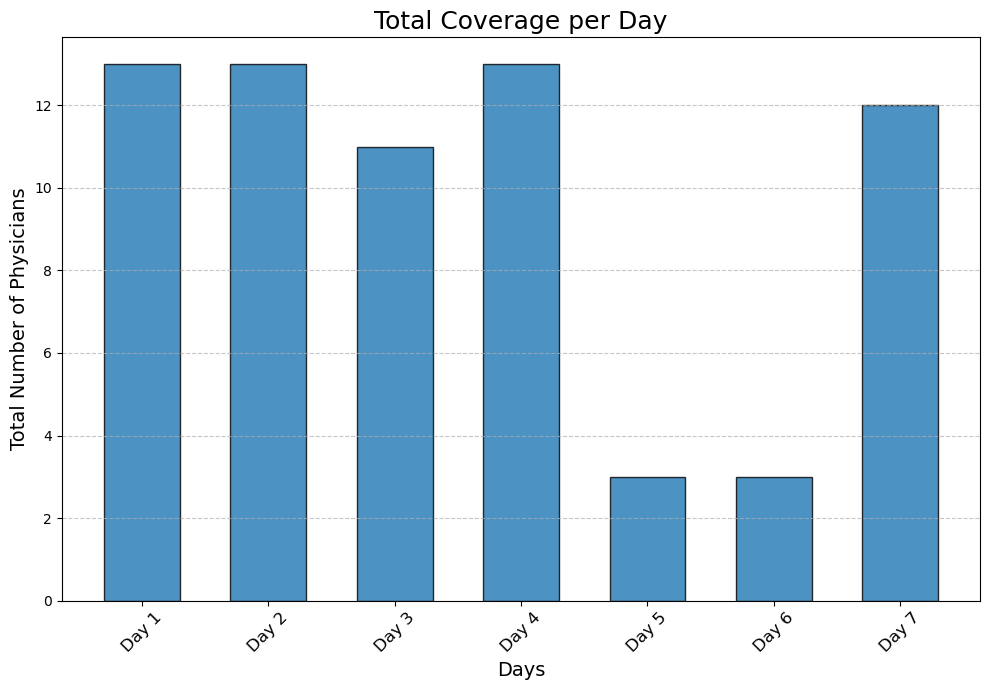

In [12]:
# Bar Chart: Shift Coverage
plt.figure(figsize=(10, 7))
width = 0.3  # Width of the bars
x = np.arange(len(df.index))  # Positions for the groups

# Add bars for each shift coverage
for i, shift in enumerate(["early", "late", "night"]):
    plt.bar(x + i * width, df[shift], width, label=f"{shift.capitalize()} Shift", alpha=0.8, color=f"C{i}")

# Add labels and title
plt.title("Shift Coverage", fontsize=18)
plt.ylabel("Number of Physicians", fontsize=14)
plt.xlabel("Days", fontsize=14)
plt.xticks(x + width, df.index, fontsize=12, rotation=45)
plt.legend(title="Shift Type", fontsize=12, title_fontsize=14)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# Bar Chart: Total Coverage per Day
plt.figure(figsize=(10, 7))
total_coverage = df.sum(axis=1)
plt.bar(total_coverage.index, total_coverage, color="C0", alpha=0.8, edgecolor="black", width=0.6)

# Add labels and title
plt.title("Total Coverage per Day", fontsize=18)
plt.ylabel("Total Number of Physicians", fontsize=14)
plt.xlabel("Days", fontsize=14)
plt.xticks(fontsize=12, rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


In [13]:
import pandas as pd

# Sicherstellen, dass die Indizes von df numerisch sind (Day X → X)
df.index = df.index.str.extract(r'(\d+)')[0].astype(int)

# First, add a column that maps each day (from the entire data set) to a week day (1 through 7).
data_df['week_day'] = ((data_df['day'] - 1) % 7) + 1

# Prepare to collect simulation results.
simulation_results = []

# Loop over each weekly column (each historical week)
for week_col in weekly_columns:
    # For each day in a cyclic week (days 1 to 7)
    for day in range(1, 8):
        # For each shift type
        for shift in ['early', 'late', 'night']:
            # Filter the data_df for rows corresponding to the given week_day and shift.
            # (Remember: a shift in our data covers 8 consecutive hours.)
            df_subset = data_df[(data_df['week_day'] == day) & (data_df['shift'] == shift)]
            # Sum the hourly demand over the 8 hours that belong to this shift for this day in the given week.
            demand_hours = df_subset[week_col].sum()
            
            # Retrieve the scheduled number of physicians for this day/shift from our schedule (`df` instead of `pivoted_results`).
            scheduled_physicians = df.loc[day, shift] if (day in df.index and shift in df.columns) else 0
            # Since each physician covers 8 hours, the scheduled capacity (in physician-hours) is:
            scheduled_capacity = scheduled_physicians * 8
            
            # Compute undercoverage (if demand exceeds capacity).
            undercoverage = max(0, demand_hours - scheduled_capacity)
            
            # Compute utilization as the fraction of scheduled capacity that was “used” (capped at 100%).
            utilization = min(demand_hours, scheduled_capacity) / scheduled_capacity if scheduled_capacity > 0 else 0
            
            # Save the results for this week/day/shift combination.
            simulation_results.append({
                'Week': week_col,
                'Day': day,
                'Shift': shift,
                'Demand_hours': demand_hours,
                'Scheduled_capacity': scheduled_capacity,
                'Undercoverage': undercoverage,
                'Utilization': utilization
            })

# Convert the simulation results to a DataFrame for further analysis.
sim_df = pd.DataFrame(simulation_results)

# --- Aggregating the simulation results ---

# Total undercoverage (in physician-hours) per shift over all historical weeks.
undercoverage_summary = sim_df.groupby('Shift')['Undercoverage'].sum()
print("Total Undercoverage (physician-hours) per Shift (over all simulated weeks):")
print(undercoverage_summary)

# Overall total undercoverage (across all shifts and weeks)
total_undercoverage = sim_df['Undercoverage'].sum()
print(f"\nOverall Total Undercoverage: {total_undercoverage:.2f} physician-hours")

# Compute average utilization per shift (expressed as a percentage)
utilization_summary = sim_df.groupby('Shift')['Utilization'].mean() * 100
print("\nAverage Utilization (%) per Shift (over all simulated weeks):")
print(utilization_summary)

# Overall average utilization across all shifts:
overall_avg_utilization = sim_df['Utilization'].mean() * 100
print(f"\nOverall Average Utilization: {overall_avg_utilization:.2f}%")


Total Undercoverage (physician-hours) per Shift (over all simulated weeks):
Shift
early    323
late     265
night    200
Name: Undercoverage, dtype: int64

Overall Total Undercoverage: 788.00 physician-hours

Average Utilization (%) per Shift (over all simulated weeks):
Shift
early    76.477466
late     62.372449
night    55.994898
Name: Utilization, dtype: float64

Overall Average Utilization: 64.95%


In [14]:
#pd.set_option('display.max_rows', None)
sim_df

,Week,Day,Shift,Demand_hours,Scheduled_capacity,Undercoverage,Utilization
0,Week 1,1,early,81,72,9,1.0
1,Week 1,1,late,29,16,13,1.0
2,Week 1,1,night,8,16,0,0.5
3,Week 1,2,early,85,72,13,1.0
4,Week 1,2,late,18,16,2,1.0
...,...,...,...,...,...,...,...
289,Week 14,6,late,0,8,0,0.0
290,Week 14,6,night,0,8,0,0.0
291,Week 14,7,early,79,72,7,1.0
292,Week 14,7,late,22,16,6,1.0


Based on the calculations above, the detailed answers to Question 3 part a, b, c is below.

**Q3-a) Total Undercoverage:**
- From the simulation we see that, when comparing the scheduled capacity (i.e., the number of physicians assigned to each 8‑hour shift multiplied by 8) with the actual hourly demand rolled up into shifts, the overall undercoverage amounts to 788 physician‑hours across all simulated weeks. Breaking this down by shift type, the early shifts have an undercoverage of 323 physician‑hours, late shifts 265, and night shifts 200. This means that, on average, there are substantial periods where the actual demand exceeds the scheduled capacity, indicating that the schedule is not always sufficient to meet the hourly demands observed in historical data. 
***
**Q3-b) Average Utilization:**
- Utilization is computed as the ratio of the “used” capacity (i.e., the minimum of demand and scheduled capacity) to the total scheduled capacity. The simulation results show that the early shifts have an average utilization of approximately 76.5%, the late shifts about 62.4%, and the night shifts around 56.0%. Overall, the schedule achieves an average utilization of roughly 65%. This indicates that—despite some periods of high demand—the capacity is often underutilized, meaning that the staffing levels are sometimes higher than needed and sometimes too low to cover peak demand, leading to a notable degree of imbalance. 
***
**Q3-c) Discussion and Implications of the Assumptions:**
- While the deterministic model in Q2 guarantees full coverage for the assumed (average) demand based on past data, it does not account for variability. In practice, if demand fluctuates (and especially during peak hours), the deterministic schedule may result in undercoverage even though the model “meets” the planned demand of past data. 
- This observation is one of the motivations for the stochastic model in Q4, which explicitly considers demand variability by allowing a small expected undercoverage (up to 1 physician‑hour per shift) to balance cost against service level.
- We acknowledge that the uncovered shifts seen in the simulation are not an error in the Q2 model but rather an indication that using average values may miss peak demand scenarios. In a real-world setting, this suggests that either the deterministic model should be modified to include buffers for variability or a stochastic approach (as in Q4) should be employed to better capture demand fluctuations.



In [17]:
import gurobipy as gp
from gurobipy import GRB

# ======== Prepare Data Parameters for the Stochastic Model ========
# We assume 'data_df' is already loaded and has columns for each week (e.g., "Week 1", "Week 2", …)
# and that we have already created the 'week_day' column (values 1 to 7) as in our earlier code.

# Define the sets
scenarios = weekly_columns  # List of week labels, e.g., ["Week 1", "Week 2", ..., "Week 14"]
days_list = [1, 2, 3, 4, 5, 6, 7]
shifts_list = ['early', 'late', 'night']

# Pre-calculate the demand for each scenario, day, and shift.
# demand_dict[omega][d][s] = total physician-hours demand in scenario ω on day d in shift s.
demand_dict = {}
for omega in scenarios:
    demand_dict[omega] = {}
    for d in days_list:
        demand_dict[omega][d] = {}
        for s in shifts_list:
            # Filter for the given week_day and shift.
            df_subset = data_df[(data_df['week_day'] == d) & (data_df['shift'] == s)]
            # Sum the hourly demand (for the 8 hours that define the shift) in scenario omega.
            demand_hours = df_subset[omega].sum()
            demand_dict[omega][d][s] = demand_hours

# ======== Build the Stochastic Optimization Model ========
# Upper bound on the number of physicians (adjust as needed)
max_physicians = 30 #Big M

model_stoch = gp.Model("Stochastic_Physician_Scheduling")

# Decision Variables:
# x[p,s,d] = 1 if physician p is scheduled for shift s on day d.
x = model_stoch.addVars(max_physicians, shifts_list, days_list, vtype=GRB.BINARY, name="x")

# y[p] = 1 if physician p is used (i.e., works at least one shift).
y = model_stoch.addVars(max_physicians, vtype=GRB.BINARY, name="y")

# Linking constraint: if physician p is assigned to any shift, then y[p] must be 1.
for p in range(max_physicians):
    for s in shifts_list:
        for d in days_list:
            model_stoch.addConstr(x[p, s, d] <= y[p], name=f"link_{p}_{s}_{d}")

# Emergency requirement: at least one physician per shift.
for s in shifts_list:
    for d in days_list:
        model_stoch.addConstr(gp.quicksum(x[p, s, d] for p in range(max_physicians)) >= 1,
                                name=f"min_one_{s}_{d}")

# Undercoverage variables: u[omega,d,s] ≥ 0, capturing any shortfall (in physician-hours)
u = model_stoch.addVars(scenarios, days_list, shifts_list, lb=0, vtype=GRB.CONTINUOUS, name="u")

# Link u variables to the scheduled capacity:
# For each scenario, day, and shift:
# u[omega,d,s] ≥ demand - 8 * (number of physicians scheduled for that shift)
for omega in scenarios:
    for d in days_list:
        for s in shifts_list:
            model_stoch.addConstr(
                u[omega, d, s] >= demand_dict[omega][d][s] - 8 * gp.quicksum(x[p, s, d] for p in range(max_physicians)),
                name=f"under_{omega}_{d}_{s}"
            )

# Expected undercoverage constraint:
# The average undercoverage for each shift (across scenarios) must be ≤ 1 physician-hour.
num_scenarios = len(scenarios)
for d in days_list:
    for s in shifts_list:
        model_stoch.addConstr(
            gp.quicksum(u[omega, d, s] for omega in scenarios) / num_scenarios <= 1,
            name=f"exp_under_{d}_{s}"
        )

# ========= Additional Scheduling Constraints =========
# 1. A physician can work at most one shift per day.
for p in range(max_physicians):
    for d in days_list:
        model_stoch.addConstr(gp.quicksum(x[p, s, d] for s in shifts_list) <= 1,
                                name=f"one_shift_per_day_{p}_{d}")

# 2. Maximum weekly shifts: at most 5 shifts per week (i.e., 40 hours).
for p in range(max_physicians):
    model_stoch.addConstr(gp.quicksum(x[p, s, d] for s in shifts_list for d in days_list) <= 5,
                            name=f"max_shifts_{p}")

# 3. Maximum consecutive night shifts: no more than 3 consecutive nights.
for p in range(max_physicians):
    for d in range(1, 5):  # For blocks of 4 consecutive days (with 7 days in a week)
        model_stoch.addConstr(gp.quicksum(x[p, "night", d + i] for i in range(4)) <= 3,
                                name=f"max_consec_night_{p}_{d}")

# 4. Shift type restriction: each physician can work at most 2 types of shifts per week.
# Introduce auxiliary binary variables: z[p,s] = 1 if physician p works shift type s at least once.
z = model_stoch.addVars(max_physicians, shifts_list, vtype=GRB.BINARY, name="z")
for p in range(max_physicians):
    for s in shifts_list:
        for d in days_list:
            model_stoch.addConstr(x[p, s, d] <= z[p, s], name=f"shift_type_link_{p}_{s}_{d}")
    model_stoch.addConstr(z[p, "early"] + z[p, "late"] + z[p, "night"] <= 2,
                          name=f"two_shift_types_{p}")

# 5. Rest constraints: if a physician works a late or night shift on day d, they cannot work the early shift on day d+1.
for p in range(max_physicians):
    for d in range(1, 7):  # Days 1 to 6 (cyclic scheduling prevents a late->early pattern from Day 7 to Day 1)
        model_stoch.addConstr(x[p, "late", d] + x[p, "early", d + 1] <= 1, name=f"rest1_{p}_{d}")
        model_stoch.addConstr(x[p, "night", d] + x[p, "early", d + 1] <= 1, name=f"rest2_{p}_{d}")

# ========= Objective: Minimize the Number of Physicians Used =========
model_stoch.setObjective(gp.quicksum(y[p] for p in range(max_physicians)), GRB.MINIMIZE)

# Optimize the model
model_stoch.optimize()

# ========= Extract and Print the Schedule =========
if model_stoch.status == GRB.OPTIMAL:
    used_physicians = [p for p in range(max_physicians) if y[p].X > 0.5]
    print(f"\nNumber of physicians used: {len(used_physicians)}")
    for p in used_physicians:
        for d in days_list:
            for s in shifts_list:
                if x[p, s, d].X > 0.5:
                    print(f"Physician {p} works {s} shift on Day {d}")
else:
    print("No optimal solution found.")


Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 11.0 (26100.2))

CPU model: Intel(R) Core(TM) i7-8565U CPU @ 1.80GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 2346 rows, 1044 columns and 15108 nonzeros
Model fingerprint: 0x80444cb5
Variable types: 294 continuous, 750 integer (750 binary)
Coefficient statistics:
  Matrix range     [7e-02, 8e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 9e+01]
Found heuristic solution: objective 30.0000000
Presolve removed 1087 rows and 256 columns
Presolve time: 0.04s
Presolved: 1259 rows, 788 columns, 5626 nonzeros
Variable types: 34 continuous, 754 integer (750 binary)

Root relaxation: objective 1.676250e+01, 891 iterations, 0.03 seconds (0.01 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | 

**Q4 Explanation and Discussion**
***

**i) Number of Physicians Required:** 
- The output from the model shows that 19 physicians are used in the optimal schedule.

***
**ii) Comparison with the Q2 Model (deterministic model):**
- The deterministic model requires full coverage based on the average demand, so it “overstaffs” to be safe, resulting in 26 physicians. The stochastic model, however, makes a trade-off between cost (or number of physicians) and service level. By accepting a slight undercoverage on average (which might be tolerable or could be compensated by), the model finds that 19 physicians suffice to meet the overall requirements.
- In many practical applications, especially in healthcare, it can be acceptable to allow a small controlled shortfall (which might be mitigated by on-call staff or by other operational adjustments) rather than overstaffing to cover every peak exactly. This trade-off can lower costs while still maintaining service levels within acceptable bounds.


***

**iii) Impact of Model Constraints/Assumptions:**
- In Question 2, the schedule was designed deterministically to cover the demand every hour without any allowance for shortfalls. This rigid coverage requirement forced the use of more physicians to ensure that every shift was covered.
- In Question 4, the model relaxes this requirement by permitting a small expected undercoverage (up to 1 physician-hour per shift). This relaxation allows the model to “hedge” against variability in demand scenarios and meet the average demand level more efficiently.
- Therefore, the strict full-coverage assumption in the deterministic model from Q2 was the primary driver for requiring a higher number of physicians. Allowing a controlled level of undercoverage in the Q4 stochastic model reduces the staffing requirements while still keeping the service level within acceptable bounds.
- To sum up, by permitting a slight average undercoverage (up to 1 physician‑hour per shift), the stochastic model accepts that in some scenarios a shift’s 8‑hour capacity might be 1 employee-hour short compared to demand. This relaxation allows the overall staffing level to be reduced (from 26 to 19 physicians in our case) because the model does not require that every shift’s demand be fully met at all times—it only requires that, on average, the shortfall is limited.

***


**Q5 Discussion**

One way to improve the schedule is to introduce greater flexibility in the assignment of shifts while still keeping each shift at 8 hours. For example, instead of strictly enforcing two consecutive days off or limiting physicians to only two types of shifts per week, the hospital could allow more varied shift combinations or even permit shorter blocks of days off if needed. This might include options such as allowing some physicians to work three consecutive shifts if they prefer, with compensatory time off later, or introducing on‐call or split-shift arrangements that better match peak demand periods. Such flexibility can lead to a more responsive schedule that adapts to real-time demand fluctuations and personal preferences.
***
**Advantages for the hospital:**  
- Financial Benefits: More flexible scheduling can reduce the need for overstaffing during low-demand periods and minimize expensive overtime.
- Improved Coverage: The schedule can better adapt to variability in patient demand, potentially enhancing service levels during peaks.
***
**Advantages for physicians:**  
- Enhanced Autonomy: Physicians may appreciate having a say in their schedules, leading to improved job satisfaction.
- Potential for Better Work–Life Balance: Flexible options can allow physicians to tailor their work periods around personal needs, although this depends on how the flexibility is managed.
***
**Disadvantages for the hospital:**  
- Complexity in Management: More flexible scheduling systems require sophisticated planning and could introduce complexity in ensuring that all regulatory and operational standards are met.
- Risk of Understaffing: If flexibility is not carefully managed, there could be periods of insufficient coverage, impacting patient care.
***
**Disadvantages for physicians and patients:**  
- Disruption to Bio-Rhythms: Unpredictable or irregular shift patterns may negatively affect physicians’ circadian rhythms and overall well-being.
- Quality of Care Concerns: For patients, too much variability might mean that care is provided by physicians who are fatigued or whose schedules vary too widely, which could impact continuity of care.
***
In summary, while increasing schedule flexibility and relaxing some of the strict constraints (such as rigid shift type restrictions and mandatory consecutive days off) could improve overall efficiency and reduce costs, it must be balanced against potential risks to employee well-being and the quality of patient care. If implemented with safeguards (like monitoring fatigue levels, ensuring fair distribution of less desirable shifts, and providing adequate recovery time), the advantages can outweigh the disadvantages, making the approach beneficial for all stakeholders.